In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from pyplot_slider import plot_surface_slider



def ravel(d, e):
    i, j = d
    _, n = e
    return (i)*n + (j)

def power_matrix(A, n):
    E, V = np.linalg.eig(A)
    return V @ np.diag(E**n) @ np.linalg.inv(V)



d = 20
r = 0.025
x = np.linspace(-25, 25, d)
y = np.linspace(-25, 25, d)
np.random.seed(33)
Z = np.random.randint(-d, d, (d, d))
m, n = Z.shape
X, Y = np.meshgrid(x, y)


K = np.zeros((Z.size, Z.size))
for p in range(Z.size):
    i, j = np.unravel_index(p, Z.shape)
    
    if (i == 0) | (i == d-1) | (j == 0) | (j == d-1):
        K[p, p] = 1
        continue

    K[p, p] = 1 - 4*r

    neighbours = (
        (i+1, j),
        (i, j+1),
        (i-1, j),
        (i, j-1)
    )
    for n1, n2 in neighbours:
        q = ravel((n1, n2), Z.shape)
        K[p, q] = r

surface = []
three_frames_for_matplot = []
A = Z.copy()
for step in np.linspace(1, 5, 101):
    u = A.reshape(A.size)
    Q = power_matrix(K, step)
    U = Q @ u
    A = U.reshape(d, d)
    surface.append(A)
    if step == 1:
        three_frames_for_matplot.append(A)
    if step == 1.28:
        three_frames_for_matplot.append(A)
    if step == 2:
        three_frames_for_matplot.append(A)
        
    
plot_surface_slider(
    X,
    Y,
    surface,
    zlim=d,
    frame_duration=40,
    transition_duration=40
)


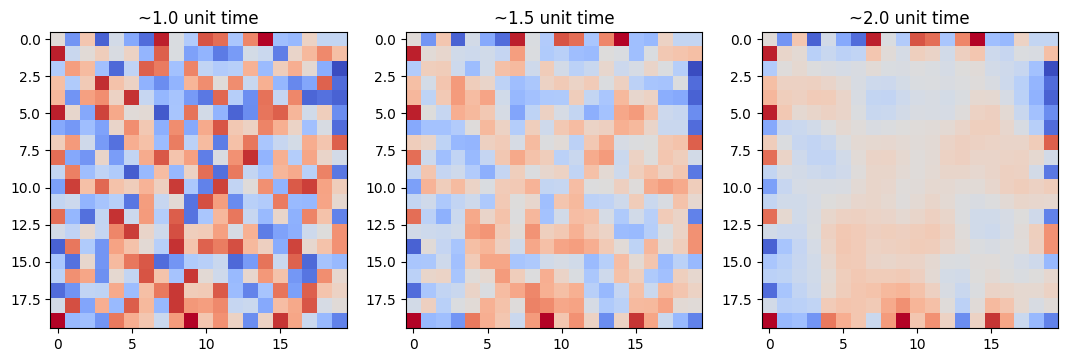

In [2]:
vmin = min(np.min(frame) for frame in three_frames_for_matplot)
vmax = max(np.max(frame) for frame in three_frames_for_matplot)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for i, ax in enumerate(axes):
    ax.imshow(three_frames_for_matplot[i], cmap="coolwarm", vmax=vmax, vmin=vmin)
    ax.set_title(f'~{1 + i * 0.5} unit time')
    
plt.show()